## Overview

In this assignment we will be predicting stroke. There are three learning outcomes:

  1. To be able to consider relevant metrics for a given prediction task

  2. To evaluate trade-offs in the data inclusion process
    
  3. To be able to read existing Python files and understanding their functionality

This notebook will focus on the first outcome. 

Please note that because you will be working in both the Jupyter notebook and a Python file, you may need to reload the Python modules imported from the Python files you are editing. For example, any changes you make to your .py files will not register with Jupyter unless you restart the notebook kernel, or follow the instructions below. 


You can either restart your notebook kernel and re-run the notebook cells or you can use the python `reload` module to ensure that you are using the latest version of the Python modules that you are editing. For example, if you have two Python files (`find_best_hyperparameters` and `data_cleaners`) then to access methods in each file you'll have to first `import importlib` and then use `importlib.reload(module or alias)`. As defined in this file, `find_best_hyperparameters` is aliased to `fbh`, so to reload the methods in `find_best_hyperparameters` you would:

```
import importlib
importlib.reload(fbh)
```
For simplicity, we have enabled the AUTORELOAD function for this notebook. This will automatically reload the module, making the interaction between python and jupyter smoother. 
NOTE: THIS WILL ONLY WORK IN THIS FIRST WEEK. FROM WEEK 2 ONWARD RELOAD WILL NOT WORK.

In some settings, such as settings within industry, it may be sufficient to train models in order to optimize a single metric, such as accuracy. However, in healthcare settings careful consideration should be given to the chosen metric, and the decision of which metric is best for the task may be the result of conversations between multiple stakeholders. 

This week, we'll start by reviewing various components of supervised learning systems, with an emphasis on evaluation metrics. Next week we will go more in depth on the topic of feature construction, selection and training. 

## Pipeline task overview: Predicting stroke

Recall from your previous courses that these tasks can typically be described by the following components: 

 1. Data collection - <font color='green'>Done</font>
 2. Data cleaning / transformation - <font color='green'>Done</font>
 3. Dataset splitting <font color='magenta'>You will do in notebook 1b </font>
 4. Model training <font color='magenta'>You will do</font>
 5. Model evaluation <font color='magenta'>You will do</font>
 6. Repeat 1-5 to perform model selection <font color='magenta'>You will do</font>
 7. Presenation of findings (Visualization) <font color='green'>Not required</font>


When training a model we may go through various phases of training and testing, while iterating on model development. This process will be the first focus of this notebook.  
![Flowchart of Grid Search Workflow](assignment1/training.png)

Source: [Scikit-Learn's Cross-validation documentation](https://scikit-learn.org/stable/modules/cross_validation.html)

In [1]:
import warnings
warnings.simplefilter("ignore")

import sys
import os
from mads.lib.path import assets

data_cleaners = assets.find("shared_files/assignment1/data_cleaners.py")
sys.path.append(os.path.dirname(data_cleaners))
import data_cleaners as dc

In [2]:
stroke_data = dc.StrokeKaggle()

In [3]:
import numpy as np
np.random.seed(681)

n_folds_dummy_data = 5
dummy_data = np.random.rand(100,4)
dummy_data_indices = np.arange(dummy_data.shape[0])

## Task ZeroA
You've seen k-fold cross-validation before. This week you will need to customize the validation process and without using the built-in packages. This task will give you a practice in separating data into two parts:  a final-held test set and a development set. The development set is then repeatedly (k-times) partitioned into training and validation sets.

The figure below demonstrates this process when setting k to 5. 

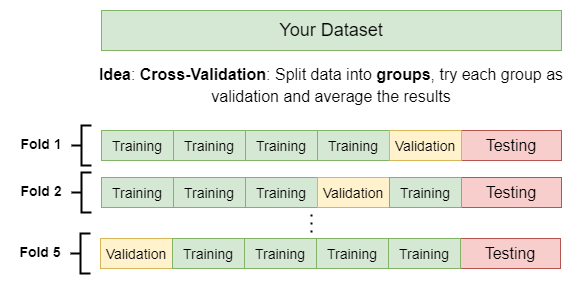

You see that the test set is shown in red. It is never used during development. During development we repeatedly train our model using 80% of the data. This 80% makes up the training set. We then evaluate the model on the remainding 20%, or the validation set. 

Let's say we want to decide whether we should use an `l2` penalty or not in our `Logistic Regression` model. We would do the following: 

```python 
accuracies = {'l2':[],'none':[]}
for penalty in [l1,None]:
    
    for fold in [1,2,3,4,5]:
        train,val = get_fold_info(fold)
        model = LogisticRegression(penalty = penalty)
        model.fit(train['X'], train['y'])
        labels = model.predict(val['X'])
        score = accuracy_score(val['y'],labels)
        accuracies[penalty].append(score)
scores = {k:sum(v)/len(v) for k,v in accuracies.items()}
if scores['l2']>scores['none']:
    print('We should use l2 penalty')
else:
    print('We should NOT use l2 penalty')

```

Here get fold info is a process which we hide. Next, you will work on separating your data into this format of test and development, where development is further separated into k-folds. 

In [ ]:
def test_split(dummy_data_indices):

    # randomly split observations into development and test sets
    # keep test observations separate to evaluate performance on unseen data
    
    # TODO: Divide the dummy_data_indices array into development and testing indices data
    # We would like to have 80 samples for development and 20 samples for testing.

    # TODO, *HINT* :- Have a look at np.random.choice function.
    # randomly select 80 unique indices for development
    training_validation_dummy_indices = np.random.choice(dummy_data_indices, size = 80, replace = False) 

    # TODO, *HINT* :- You would want to look for function which can do set difference
    # select the remaning 20 indices for final testing
    test_set_dummy_indices = np.setdiff1d(dummy_data_indices, training_validation_dummy_indices)
    
    return training_validation_dummy_indices, test_set_dummy_indices

In [5]:
dev, test = test_split(dummy_data_indices)

print("Development observations:", len(dev))
print("Test observations:", len(test))
print("Overlap:", len(np.intersect1d(dev, test)))

Development observations: 80
Test observations: 20
Overlap: 0


In [6]:
#hidden tests are within this cell

## Task ZeroB

We have divided the total dataset into a development and a test set. Now we want to divide the development set further into training and validation. 

Your task here is to divide the development data into training and validation data. To do so you will create the following dictionary: ``dummy_folds`` . 

``dummy_folds`` is utilized for storing the training and validation indices in the following format...

```p
{
fold_id : [list_of_indices_to_train_on, list_of_indices_to_test_on]
}
```

In [ ]:
def training_validation_split(training_validation_dummy_indices):

    # shuffle and divide development data into five folds
    # use four folds for training and one for validation
    # rotate validation folds so each observation is evaluated once

    dummy_folds = {} # Initialize the dictionary to collect the training and validation indices of each fold

    # shuffle the 80 development indices
    shuffled_indices = np.random.permutation(training_validation_dummy_indices)

    # divide the indices into 5 equal folds
    folds = np.array_split(shuffled_indices, 5)
    
    # TODO: Divide the TrainingValidationDummy_indices array into training and
    # testing indices data. 
    # create training and validation indices for each fold
    for i in range(5):
        # use one fold for validation
        validation_indices = folds[i]

        # combine the remaining 4 folds for training
        training_indices = np.concatenate(
            [folds[j] for j in range(5) if j != i])

        # store both sets in the dictionary
        dummy_folds[i] = [
            training_indices.tolist(),
            validation_indices.tolist()]
    # *HINT* :- See the visualization figure of cross validation for an example.
    
    return dummy_folds

In [8]:
# create 100 dummy observation indices
dummy_data_indices = np.arange(100)

# split into 80 development and 20 test observations
training_validation_dummy_indices, test_set_dummy_indices = test_split(
    dummy_data_indices
)

In [9]:
dummy_folds = training_validation_split(
    training_validation_dummy_indices
)

for fold_id, (train, val) in dummy_folds.items():
    print(
        f"Fold {fold_id}: "
        f"Training = {len(train)}, "
        f"Validation = {len(val)}, "
        f"Overlap = {len(set(train) & set(val))}"
    )

Fold 0: Training = 64, Validation = 16, Overlap = 0
Fold 1: Training = 64, Validation = 16, Overlap = 0
Fold 2: Training = 64, Validation = 16, Overlap = 0
Fold 3: Training = 64, Validation = 16, Overlap = 0
Fold 4: Training = 64, Validation = 16, Overlap = 0


In [10]:
#hidden tests are within this cell


Now that we've have seen the general construction of training, validation, and testing sets within the context of cross validation utilizing dummy data, it is now time to shift our focus to the actual data. Good News! **We have covered you this time. You don't need to do the data cleaning process again for the actual data. We have done it for you.**

A few things we would like you to keep in mind before proceeding. The data structure remains the same as above. When you call ```empty,folds = stroke_data.get_all_train_test_indices_ng() ``` folds will be a dictionary where the keys are fold ids, and the values are tuples where the first value is a list of indices for the training data for this fold, and the second value is a list of indices for the validation data for this fold. 

We still encourage you to go over ``data_cleaner.py`` file which contains our implementation of construction of the training, validation and testing sets.  

In [11]:
empty,folds = stroke_data.get_all_train_test_indices_ng() 

**Question:- If you wanted to decide the optimal value for the hyper-parameter C, using Logistic Regression and 10-fold cross validation, how many times would you need to fit a different Logistic Regression?**


In [ ]:
# Answer of above question.
# ten-fold cross-validation requires ten model fits per hyperparameter setting
answer = 10

With 10-fold cross-validation, we train the model 10x for each candidate value of C.

For one value of C:
- 9 folds are used for training
- 1 fold is used for validation

The process repeats 10x, changing the validation fold.

*Question does not specify how many candidate value are being tested, we are assuming that there is only one for c.

For example, if we test 7 different values of c, we would need 7 x 10 = 70 model fits in total. 

In [13]:
#hidden tests are within this cell

We are going to start by looking at the accuracy of a logistic regression model. 

The code in find_best_hyperparameters is almost all implemented. All you need to do is update the missing line with  Sklearn's LogisticRegression model. 

After running the following lines you should see the output below

```
results
[('l2-0.1', 0.7482078819132327),
 ('l2-10', 0.7466866158868335),
 ('l2-100', 0.7466866158868335),
 ('none-0.001', 0.7466866158868335),
 ('none-0.01', 0.7466866158868335),
 ('none-0.1', 0.7466866158868335),
 ('none-1.0', 0.7466866158868335),
 ('none-10', 0.7466866158868335),
 ('none-100', 0.7466866158868335),
 ('l2-1.0', 0.7464689880304679),
 ('l2-0.01', 0.7408132658371575),
 ('l2-0.001', 0.7264609452618631)]
 
 ```

In [14]:
find_best_hyperparameters = assets.find("shared_files/assignment1/find_best_hyperparameters.py")
sys.path.append(os.path.dirname(find_best_hyperparameters))
import find_best_hyperparameters as fbh

In [15]:
%load_ext autoreload 
%autoreload 2

## <font color='magenta'>Task One A</font>

Throughout the course you will be editing python files with existing code. Before you get started you should read through the code and make sure you understand it in its entirety. This is good practice to make sure you don’t waste time repeating existing functionality that has already been completed or “break” code that someone else has already perfected. There may be an existing function that makes your life easier which you can use to accomplish your task. 

Another clue is to check the way the function is called, e.g. see ``fbh.run_gridsearch_all_evaluate_group(...)`` and pay attention to the arguments being passed in. 

You will need to make edits to the file  ```find_best_hyperparameters```. See line 4 in the cell below for more context.

In [ ]:
# once you have completed the code in find_best_hyperparameters.py, then uncomment the following line

# compare hyperparameter combinations using cross-validation accuracy
# rank models by their average accuracy across folds
results = fbh.run_gridsearch_all_evaluate_all(folds,stroke_data,'accuracy')


In [17]:
results

#hidden tests are within this cell

[('l2-0.1', 0.7482078819132327),
 ('l2-10.0', 0.7469040071911813),
 ('l2-100.0', 0.7469040071911813),
 ('None-0.001', 0.7469040071911813),
 ('None-0.01', 0.7469040071911813),
 ('None-0.1', 0.7469040071911813),
 ('None-1.0', 0.7469040071911813),
 ('None-10.0', 0.7469040071911813),
 ('None-100.0', 0.7469040071911813),
 ('l2-1.0', 0.7464689880304679),
 ('l2-0.01', 0.7410306571415054),
 ('l2-0.001', 0.7264609452618631)]

This accuracy looks high. Is it? 

A good sanity check for interpreting an accuracy score is to look at the performance of the baseline model, called the majority class model. So, if you predict the most common class for each data point what would your performance be? 

For example, if our labels looked like this [0,0,0,0,1] the majority class baseline would predict [0,0,0,0,0] and the accuracy would be 1 -  1/5 or 80\%. 

For this dataset what fraction of the labels are 1s? 

## <font color='magenta'>Task One B</font>

Fill out the function ```calculate_proportion_positive_labels```

Your function should return the proportion of positive labels in stroke data. This is the proportion of values in the column y with a value of 1. 

In [ ]:
def calculate_proportion_positive_labels():

    # calculate the proportion of patients with stroke = 1

    # calculate stroke prevalence using the mean of binary labels
    # identify the majority class to establish a baseline for accuracy
    proportion = stroke_data.y.mean()

    return proportion 

In [ ]:
# calculate the proportion of patients who experienced a stroke
print('Proportion of 1 labels {}'.format(calculate_proportion_positive_labels()))

# identify the majority class based on stroke prevalence
if calculate_proportion_positive_labels()>.5:
    print("Majority class is 1")
else:
    print("Majority class is 0")    

Proportion of 1 labels 0.0487279843444227
Majority class is 0


## <font color='magenta'>Task Two</font>

When we have class imbalance, accuracy can be a misleading metric. It can appear high even when the model is not learning well. 

In these settings we may want to use a metric such as f-measure, but this metric can be sensitive to the decision threshold. 

To see this, compute the f-measure of the logistic regression model you used earlier using decision thresholds of [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]



To do this you should:

 1. modify ```get_predictions_threshold_label``` in ```import find_best_hyperparameters as fbh``` so that it uses the LogisticRegression function `predict_proba`
 2. within this function, round the predictions using the input decision threshold so that the function ```get_predictions_threshold_label``` returns binary labels
 3. create a list of tuples where the first entry of each tuple is the decision threshold and the second entry is the f-measure, see below

```p
results = [(d,stroke_data.run_gridsearch_all_evaluate_all(folds,model,'f1',threshold=d)) for d in  \
           [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]]
```
   

        

In [ ]:
# once you have completed the code in find_best_hyperparameters.py, then uncomment the following lines

# evaluate f1 scores across different classification thresholds
# compare how the threshold affects model performance
results = [(d,fbh.run_gridsearch_all_evaluate_all(folds,stroke_data,'f1',threshold=d)) for d in  \
           [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]]


In [21]:
results

#hidden tests are within this cell

[(0.1,
  [('l2-100.0', 0.1400117790707873),
   ('None-0.001', 0.1400117790707873),
   ('None-0.01', 0.1400117790707873),
   ('None-0.1', 0.1400117790707873),
   ('None-1.0', 0.1400117790707873),
   ('None-10.0', 0.1400117790707873),
   ('None-100.0', 0.1400117790707873),
   ('l2-10.0', 0.13996833643974355),
   ('l2-1.0', 0.13935082612072303),
   ('l2-0.1', 0.13646124298607548),
   ('l2-0.01', 0.12033975563946528),
   ('l2-0.001', 0.0931821377892296)]),
 (0.2,
  [('l2-100.0', 0.1652069487218834),
   ('None-0.001', 0.1652069487218834),
   ('None-0.01', 0.1652069487218834),
   ('None-0.1', 0.1652069487218834),
   ('None-1.0', 0.1652069487218834),
   ('None-10.0', 0.1652069487218834),
   ('None-100.0', 0.1652069487218834),
   ('l2-10.0', 0.16508098454107972),
   ('l2-1.0', 0.16502151383040475),
   ('l2-0.1', 0.1636338891945103),
   ('l2-0.01', 0.14698181367753227),
   ('l2-0.001', 0.11023263344760159)]),
 (0.3,
  [('None-0.001', 0.18895825700248975),
   ('None-0.01', 0.18895825700248975),


## <font color='magenta'>Task Three</font>


To overcome the sensitivity to the threshold we can use a metric which inspects the performance across a range of thresholds. For example, one metric which does this is the  [```average precision```](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html). 

To complete the final task of this notebook modify ```get_predictions_prob``` and ```get_scores``` to be able to handle the average precision metric. 

Then, report the results on running ```fbh.run_gridsearch_all_evaluate_all(folds,stroke_data,'average_precision'))```

In [ ]:
# once you have completed the code in find_best_hyperparameters.py, then uncomment the following line
results = fbh.run_gridsearch_all_evaluate_all(folds,stroke_data,'average_precision')

In [23]:
results

#hidden tests are within this cell

[('None-0.001', 0.21409043670370495),
 ('None-0.01', 0.21409043670370495),
 ('None-0.1', 0.21409043670370495),
 ('None-1.0', 0.21409043670370495),
 ('None-10.0', 0.21409043670370495),
 ('None-100.0', 0.21409043670370495),
 ('l2-100.0', 0.21405679290574137),
 ('l2-10.0', 0.21405432044210296),
 ('l2-1.0', 0.21384537195583828),
 ('l2-0.1', 0.2133543019865501),
 ('l2-0.01', 0.20795781740572922),
 ('l2-0.001', 0.1895449996294657)]

In [ ]:
# evaluate precision-recall performance across decision thresholds
# identify hyperparameters with the highest average precision
accuracy_results = fbh.run_gridsearch_all_evaluate_all(
    folds, stroke_data, 'accuracy'
)

print(accuracy_results[:5])
print("Selected penalty:", result_penalty_acc)

[('l2-0.1', 0.7482078819132327), ('l2-10.0', 0.7469040071911813), ('l2-100.0', 0.7469040071911813), ('None-0.001', 0.7469040071911813), ('None-0.01', 0.7469040071911813)]
Selected penalty: 12


To finish the notebook answer the following questions:

**Which penalty would you choose according to the accuracy score?**

Enter 'none' or 'l2'

In [ ]:
# select the penalty highest cross-validation accuracy
result_penalty_acc = 'l2'

In [35]:
#hidden tests are within this cell

**Which c would you choose according to the accuracy score?**

Enter a value from [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

In [ ]:
# select the c with the highest cross-validation accuracy
result_c_acc = 0.1

In [37]:
#hidden tests are within this cell

**Which penalty would you choose according to the average precision score?**

Enter 'none' or 'l2'

In [ ]:
# select the penalty with the highest average precision
result_penalty_avgprec = 'none'

In [39]:
#hidden tests are within this cell

**Which c would you choose according to the average precision score?**

Enter a value from [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

In [ ]:
# select the c value associated with the highest average precision
result_c_avg_prec = 0.001

In [41]:
#hidden tests are within this cell

## IMPORTANT: Uncomment the following code when you are ready to move on to the next assignment

In [42]:
script = assets.find('copy_shared_files.sh')
!bash {script}

=== Copying shared files back to coursework ===
✅ Shared files successfully copied back to coursework.
